# Comparación de datos climáticos: Medellín y Tokio
**Autor:** Francisco Florez  
**Periodo:** 1 de enero a 31 de diciembre de 2023.  
**Frecuencia:** diaria.

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Tokio durante el mismo periodo?

## A. Planteamiento de la comparación
**Predicción:** espero que las temperaturas máximas de Medellín cambien menos entre meses que las de Tokio y que Medellín registre mayor precipitación acumulada y más días lluviosos.

Compararemos la **temperatura máxima diaria (°C)** y la **precipitación diaria (mm)** del **1 de enero al 31 de diciembre de 2023**.

### Fuentes y variables

| Ciudad y país | Fuente | Estación | Columnas utilizadas | Periodo | Frecuencia | Unidades |
|---|---|---|---|---|---|---|
| Medellín, Colombia | IDEAM: [temperatura](https://bart.ideam.gov.co/PQRS/AQTSUtils/maxima.zip) y [precipitación](https://bart.ideam.gov.co/PQRS/AQTSUtils/PrecipitacionNacionalDiaria.zip) | Aeropuerto Olaya Herrera | `fecha`, `temperatura_maxima_c`, `precipitacion_mm` | 2023-01-01 a 2023-12-31 | Diaria | °C y mm |
| Tokio, Japón | [Agencia Meteorológica de Japón](https://www.data.jma.go.jp/stats/etrn/view/daily_s1.php?prec_no=44&block_no=47662&year=2023&month=1&day=&view=) | Tokio | `fecha`, `temperatura_maxima_c`, `precipitacion_mm`, `precipitacion_original` | 2023-01-01 a 2023-12-31 | Diaria | °C y mm |

Ambas tablas utilizan las mismas unidades; no se requiere conversión.

### Tratamiento de ceros y faltantes
Según la [documentación de JMA](https://www.data.jma.go.jp/stats/data/mdrr/man/remark.html), `--` indica ausencia del fenómeno y se representó como 0 mm, conservando el símbolo en `precipitacion_original`. El valor `0.0` puede representar una cantidad inferior a 0,5 mm. Los valores faltantes se conservan como `NaN` y no se reemplazan por cero.

Usaremos los mismos umbrales en ambas ciudades: **día lluvioso: precipitación ≥1 mm**; **día que supera el umbral térmico: temperatura máxima >30 °C**.

## B. Carga y revisión de los datos
Leemos los CSV desde `datos/` y mostramos columnas, filas y dimensiones. Convertimos fechas y mediciones y revisamos el periodo, los faltantes y las fechas duplicadas.

In [1]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path.cwd()
if not (BASE / 'datos' / 'medellin.csv').is_file():
    BASE = BASE / 'EA3_comparacion_climatica'
DATOS = BASE / 'datos'
ciudades = ['Medellín', 'Tokio']
archivos = ['medellin.csv', 'tokio.csv']
tablas = {ciudad: pd.read_csv(DATOS / archivo)
          for ciudad, archivo in zip(ciudades, archivos)}

for ciudad, tabla in tablas.items():
    print(f'\n{ciudad}: dimensiones {tabla.shape}; columnas {tabla.columns.tolist()}')
    display(tabla.head())

plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
colores = ['#147D64', '#B94B58']


Medellín: dimensiones (365, 3); columnas ['fecha', 'temperatura_maxima_c', 'precipitacion_mm']


,fecha,temperatura_maxima_c,precipitacion_mm
0,2023-01-01,26.8,5.4
1,2023-01-02,27.9,22.7
2,2023-01-03,22.5,10.0
3,2023-01-04,27.5,0.3
4,2023-01-05,25.6,7.1



Tokio: dimensiones (365, 4); columnas ['fecha', 'temperatura_maxima_c', 'precipitacion_mm', 'precipitacion_original']


,fecha,temperatura_maxima_c,precipitacion_mm,precipitacion_original
0,2023-01-01,13.0,0.0,--
1,2023-01-02,12.1,0.0,--
2,2023-01-03,11.0,0.0,--
3,2023-01-04,11.0,0.0,--
4,2023-01-05,10.6,0.0,--


In [2]:
variables = ['temperatura_maxima_c', 'precipitacion_mm']
inicio, fin = np.datetime64('2023-01-01'), np.datetime64('2023-12-31')
calendario = np.arange(inicio, fin + np.timedelta64(1, 'D'))
auditoria = []
for ciudad, tabla in tablas.items():
    faltantes_originales = tabla[['fecha'] + variables].isna().sum().to_dict()
    tabla['fecha'] = pd.to_datetime(tabla['fecha'], format='%Y-%m-%d', errors='coerce')
    for variable in variables:
        tabla[variable] = pd.to_numeric(tabla[variable], errors='coerce')
        tabla.loc[~np.isfinite(tabla[variable]), variable] = np.nan
    tabla.sort_values('fecha', inplace=True)
    fechas = tabla['fecha'].to_numpy(dtype='datetime64[D]')
    fechas_validas = fechas[~np.isnat(fechas)]
    duplicadas = int(tabla.loc[tabla['fecha'].notna(), 'fecha'].duplicated().sum())
    ausentes = np.setdiff1d(calendario, fechas_validas)
    extras = np.setdiff1d(fechas_validas, calendario)
    auditoria.append({'ciudad': ciudad, 'filas': len(tabla),
                      'fecha_inicial': str(fechas_validas.min()),
                      'fecha_final': str(fechas_validas.max()),
                      'fechas_invalidas': int(np.isnat(fechas).sum()),
                      'faltantes_temperatura': int(tabla[variables[0]].isna().sum()),
                      'faltantes_precipitacion': int(tabla[variables[1]].isna().sum()),
                      'fechas_duplicadas': duplicadas,
                      'dias_sin_fila': len(ausentes)})
    print(ciudad, 'faltantes en la lectura original:', faltantes_originales)
    print('Tipos después de convertir:', tabla[['fecha'] + variables].dtypes.to_dict())
    assert duplicadas == 0, 'Resolver fechas duplicadas antes de comparar.'
    assert len(extras) == 0 and len(fechas_validas) > 0
    assert fechas_validas.min() == inicio and fechas_validas.max() == fin
    assert not (tabla['precipitacion_mm'].dropna() < 0).any()

display(pd.DataFrame(auditoria))

# Comprobamos que los ceros derivados de -- responden a la documentación de JMA.
tokio = tablas['Tokio']
sin_fenomeno = tokio['precipitacion_original'].eq('--').to_numpy()
assert np.all(tokio.loc[sin_fenomeno, 'precipitacion_mm'].to_numpy() == 0)
print('Tokio: registros con -- (ausencia del fenómeno):', int(sin_fenomeno.sum()))
print('Tokio: registros con 0.0 original (pueden incluir trazas):',
      int(tokio['precipitacion_original'].eq('0.0').sum()))

Medellín faltantes en la lectura original: {'fecha': 0, 'temperatura_maxima_c': 0, 'precipitacion_mm': 0}
Tipos después de convertir: {'fecha': dtype('<M8[ns]'), 'temperatura_maxima_c': dtype('float64'), 'precipitacion_mm': dtype('float64')}
Tokio faltantes en la lectura original: {'fecha': 0, 'temperatura_maxima_c': 0, 'precipitacion_mm': 0}
Tipos después de convertir: {'fecha': dtype('<M8[ns]'), 'temperatura_maxima_c': dtype('float64'), 'precipitacion_mm': dtype('float64')}


,ciudad,filas,fecha_inicial,fecha_final,fechas_invalidas,faltantes_temperatura,faltantes_precipitacion,fechas_duplicadas,dias_sin_fila
0,Medellín,365,2023-01-01,2023-12-31,0,0,0,0,0
1,Tokio,365,2023-01-01,2023-12-31,0,0,0,0,0


Tokio: registros con -- (ausencia del fenómeno): 192
Tokio: registros con 0.0 original (pueden incluir trazas): 73


### Fechas válidas comunes
Construimos el calendario completo de 2023 y seleccionamos las fechas con temperatura y precipitación válidas en ambas tablas. Los faltantes permanecen como `NaN`. Contamos los días disponibles y los excluidos.

In [3]:
fechas = calendario.copy()
alineadas = [tablas[c].set_index('fecha').reindex(pd.DatetimeIndex(fechas))
             for c in ciudades]
temperatura = np.column_stack([t[variables[0]].to_numpy(dtype=float) for t in alineadas])
precipitacion = np.column_stack([t[variables[1]].to_numpy(dtype=float) for t in alineadas])
mascara_comun = (np.isfinite(temperatura).all(axis=1)
                 & np.isfinite(precipitacion).all(axis=1))
fechas_comunes = fechas[mascara_comun]
T = temperatura[mascara_comun]
P = precipitacion[mascara_comun]
print('Calendario:', len(fechas), 'días; días comunes válidos:', len(fechas_comunes),
      '; días excluidos:', int((~mascara_comun).sum()))
print('Arrays NumPy T y P: filas=días, columnas=Medellín y Tokio:', T.shape, P.shape)
assert T.shape == P.shape and T.shape[1] == 2

Calendario: 365 días; días comunes válidos: 365 ; días excluidos: 0
Arrays NumPy T y P: filas=días, columnas=Medellín y Tokio: (365, 2) (365, 2)


## C. Análisis con NumPy
### Índices y cortes
Inspeccionamos los primeros siete días de ambas ciudades mediante cortes de los arrays.

In [4]:
display(pd.DataFrame({'fecha': fechas_comunes[:7],
                      'Tmax Medellín (°C)': T[:7, 0], 'Tmax Tokio (°C)': T[:7, 1],
                      'Lluvia Medellín (mm)': P[:7, 0], 'Lluvia Tokio (mm)': P[:7, 1]}))

,fecha,Tmax Medellín (°C),Tmax Tokio (°C),Lluvia Medellín (mm),Lluvia Tokio (mm)
0,2023-01-01,26.8,13.0,5.4,0.0
1,2023-01-02,27.9,12.1,22.7,0.0
2,2023-01-03,22.5,11.0,10.0,0.0
3,2023-01-04,27.5,11.0,0.3,0.0
4,2023-01-05,25.6,10.6,7.1,0.0
5,2023-01-06,26.4,9.9,0.0,0.0
6,2023-01-07,25.0,10.4,36.2,0.0


### Máscaras booleanas y medidas descriptivas
Seleccionamos los días con precipitación ≥1 mm y temperatura máxima >30 °C. Calculamos el promedio, mínimo y máximo de la temperatura máxima diaria, la precipitación acumulada y los conteos de días seleccionados.

In [5]:
UMBRAL_LLUVIA = 1.0  # mm: se incluye el valor exacto 1 mm
UMBRAL_TEMPERATURA = 30.0  # °C: se exige superar 30 °C
dias_lluviosos = P >= UMBRAL_LLUVIA
dias_calidos = T > UMBRAL_TEMPERATURA

for j, ciudad in enumerate(ciudades):
    print(ciudad, 'primeras fechas lluviosas:', fechas_comunes[dias_lluviosos[:, j]][:5])
    print(ciudad, 'primeras máximas >30 °C:', T[dias_calidos[:, j], j][:5])

resumen = pd.DataFrame({
    'Ciudad': ciudades,
    'Días válidos': np.repeat(len(fechas_comunes), 2),
    'Promedio Tmax (°C)': np.mean(T, axis=0),
    'Mínima Tmax (°C)': np.min(T, axis=0),
    'Máxima Tmax (°C)': np.max(T, axis=0),
    'Precipitación acumulada (mm)': np.sum(P, axis=0),
    'Días con ≥1 mm': np.sum(dias_lluviosos, axis=0),
    'Días con Tmax >30 °C': np.sum(dias_calidos, axis=0)})
display(resumen.round(2))

Medellín primeras fechas lluviosas: ['2023-01-01' '2023-01-02' '2023-01-03' '2023-01-05' '2023-01-07']
Medellín primeras máximas >30 °C: [30.4 30.2 30.4 31.2 30.2]
Tokio primeras fechas lluviosas: ['2023-01-14' '2023-01-15' '2023-01-16' '2023-01-17' '2023-02-10']
Tokio primeras máximas >30 °C: [31.6 32.2 30.7 30.9 31.1]


,Ciudad,Días válidos,Promedio Tmax (°C),Mínima Tmax (°C),Máxima Tmax (°C),Precipitación acumulada (mm),Días con ≥1 mm,Días con Tmax >30 °C
0,Medellín,365,28.66,22.2,32.6,1630.7,138,99
1,Tokio,365,22.55,3.5,37.7,1396.5,90,89


### Broadcasting
Restamos a cada máxima diaria el promedio anual de su ciudad. NumPy extiende el vector de promedios, de forma `(2,)`, sobre el array de temperaturas, de forma `(n_días, 2)`. El resultado muestra cuánto se aparta cada día del promedio de 2023 de su ciudad.

In [6]:
media_por_ciudad = np.mean(T, axis=0)
desviacion = T - media_por_ciudad  # broadcasting (n, 2) - (2,) -> (n, 2)
print('Formas:', T.shape, '-', media_por_ciudad.shape, '=', desviacion.shape)
display(pd.DataFrame({'fecha': fechas_comunes[:7],
                      'Desviación Medellín (°C)': desviacion[:7, 0],
                      'Desviación Tokio (°C)': desviacion[:7, 1]}).round(2))
assert np.allclose(desviacion.mean(axis=0), 0, atol=1e-10)

Formas: (365, 2) - (2,) = (365, 2)


,fecha,Desviación Medellín (°C),Desviación Tokio (°C)
0,2023-01-01,-1.86,-9.55
1,2023-01-02,-0.76,-10.45
2,2023-01-03,-6.16,-11.55
3,2023-01-04,-1.16,-11.55
4,2023-01-05,-3.06,-11.95
5,2023-01-06,-2.26,-12.65
6,2023-01-07,-3.66,-12.15


## D. Gráficas comparativas
Agrupamos los días por mes con máscaras NumPy. Calculamos la media mensual de las máximas diarias y la precipitación acumulada mensual. Comprobamos cuántos días se utilizan en cada mes.

In [7]:
mes = fechas_comunes.astype('datetime64[M]').astype(int) % 12 + 1
meses = np.arange(1, 13)
nombres_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
                 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
temperatura_mensual = np.full((12, 2), np.nan)
precipitacion_mensual = np.full((12, 2), np.nan)
conteos = np.zeros(12, dtype=int)
for i, m in enumerate(meses):
    seleccion = mes == m
    conteos[i] = np.count_nonzero(seleccion)
    if conteos[i]:
        temperatura_mensual[i] = np.mean(T[seleccion], axis=0)
        precipitacion_mensual[i] = np.sum(P[seleccion], axis=0)
esperados = np.array([calendar.monthrange(2023, int(m))[1] for m in meses])
display(pd.DataFrame({'Mes': nombres_meses, 'Días esperados': esperados,
                      'Días comunes usados': conteos,
                      'Tmax media Medellín (°C)': temperatura_mensual[:, 0],
                      'Tmax media Tokio (°C)': temperatura_mensual[:, 1],
                      'Precipitación Medellín (mm)': precipitacion_mensual[:, 0],
                      'Precipitación Tokio (mm)': precipitacion_mensual[:, 1]}).round(2))
print('Meses con cobertura completa:', int(np.sum(conteos == esperados)), 'de 12')
assert np.allclose(np.nansum(precipitacion_mensual, axis=0), P.sum(axis=0))

,Mes,Días esperados,Días comunes usados,Tmax media Medellín (°C),Tmax media Tokio (°C),Precipitación Medellín (mm),Precipitación Tokio (mm)
0,Ene,31,31,27.20,10.25,216.3,15.5
1,Feb,28,28,28.30,12.10,43.7,40.5
2,Mar,31,31,27.08,17.90,249.5,145.0
3,Abr,30,30,27.61,21.69,164.1,90.0
4,May,31,31,29.18,23.96,195.8,159.0
5,Jun,30,30,29.13,27.55,85.9,347.0
6,Jul,31,31,29.80,33.87,104.2,30.0
7,Ago,31,31,30.13,34.27,59.8,132.5
8,Sep,30,30,30.39,31.16,97.5,229.0
9,Oct,31,31,27.54,23.68,171.2,147.0


Meses con cobertura completa: 12 de 12


### 1. Líneas: media mensual de las temperaturas máximas diarias

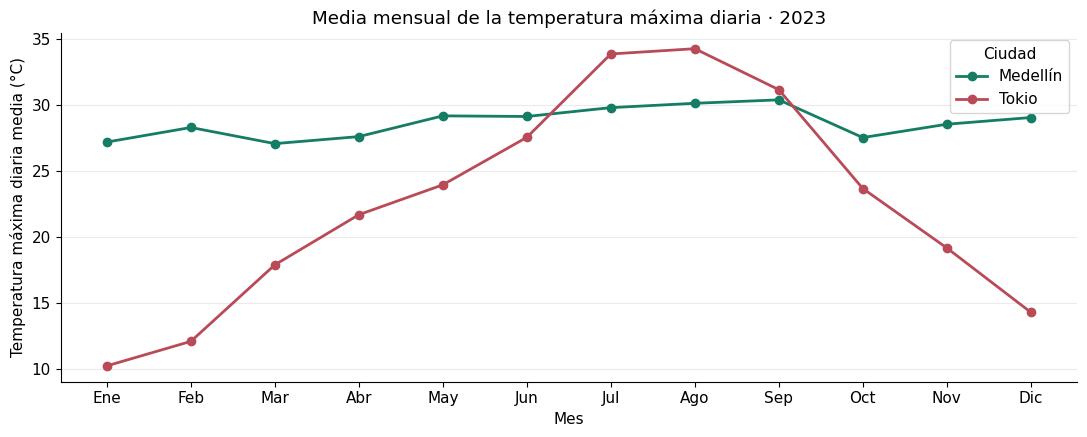

In [8]:
fig, ax = plt.subplots()
for j, ciudad in enumerate(ciudades):
    ax.plot(meses, temperatura_mensual[:, j], marker='o', linewidth=2,
            color=colores[j], label=ciudad)
ax.set(title='Media mensual de la temperatura máxima diaria · 2023',
       xlabel='Mes', ylabel='Temperatura máxima diaria media (°C)',
       xticks=meses, xticklabels=nombres_meses)
ax.grid(axis='y', alpha=0.25)
ax.legend(title='Ciudad')
fig.tight_layout()
plt.show()

In [9]:
amplitud_mensual = np.nanmax(temperatura_mensual, axis=0) - np.nanmin(temperatura_mensual, axis=0)

**Patrón observado:** la diferencia entre el mes con mayor y menor media de máximas es 3.32 °C en Medellín y 24.02 °C en Tokio. En enero, las medias son 27.20 y 10.25 °C, respectivamente; en agosto son 30.13 y 34.27 °C. **Lo que no permite concluir:** un solo año no establece una tendencia de cambio climático ni demuestra qué factor causa las diferencias. Los promedios mensuales también ocultan extremos diarios.

### 2. Barras agrupadas: precipitación acumulada mensual

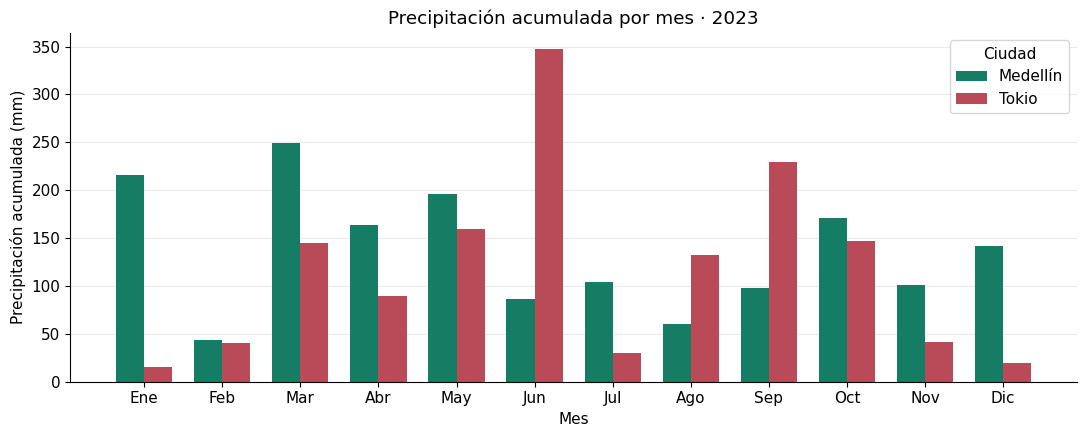

In [10]:
fig, ax = plt.subplots()
ancho = 0.36
for j, ciudad in enumerate(ciudades):
    ax.bar(meses + (j - 0.5) * ancho, precipitacion_mensual[:, j], width=ancho,
           color=colores[j], label=ciudad)
ax.set(title='Precipitación acumulada por mes · 2023', xlabel='Mes',
       ylabel='Precipitación acumulada (mm)', xticks=meses, xticklabels=nombres_meses)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title='Ciudad')
fig.tight_layout()
plt.show()

**Patrón observado:** el mayor acumulado mensual de Medellín ocurre en Mar, con 249.5 mm; el de Tokio ocurre en Jun, con 347.0 mm. En todo el periodo se acumulan 1630.7 y 1396.5 mm, respectivamente. **Lo que no permite concluir:** una barra alta no indica si hubo muchos días lluviosos o pocos eventos intensos, ni permite atribuir la precipitación a una causa concreta. Estas sumas tampoco representan promedios de muchos años.

### 3. Histogramas: distribución de las temperaturas máximas diarias
Usamos los mismos intervalos de 2 °C para ambas ciudades y señalamos el umbral de 30 °C.

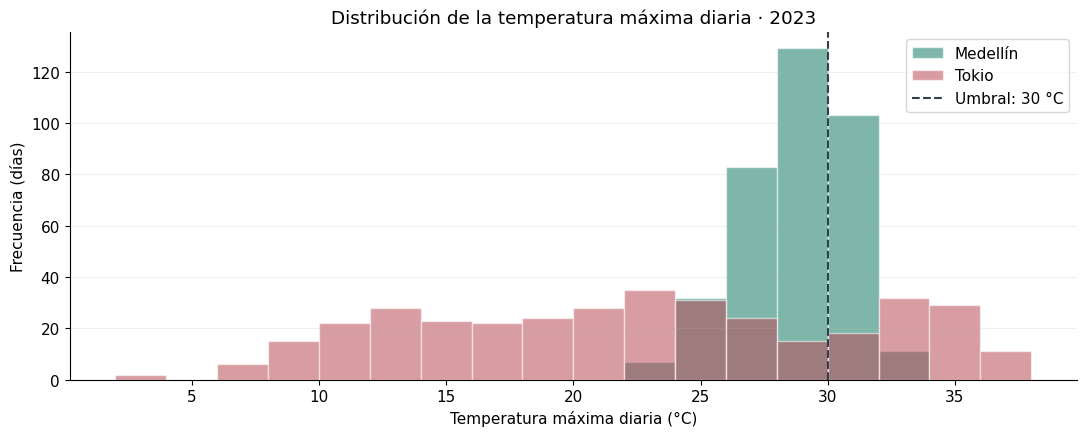

In [11]:
limite_inferior = np.floor(np.min(T) / 2) * 2
limite_superior = np.ceil(np.max(T) / 2) * 2
intervalos = np.arange(limite_inferior, limite_superior + 2, 2)
fig, ax = plt.subplots()
for j, ciudad in enumerate(ciudades):
    ax.hist(T[:, j], bins=intervalos, alpha=0.55, color=colores[j],
            edgecolor='white', label=ciudad)
ax.axvline(UMBRAL_TEMPERATURA, color='#353E4B', linestyle='--', label='Umbral: 30 °C')
ax.set(title='Distribución de la temperatura máxima diaria · 2023',
       xlabel='Temperatura máxima diaria (°C)', ylabel='Frecuencia (días)')
ax.grid(axis='y', alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

**Patrón observado:** las máximas de Medellín van de 22.2 a 32.6 °C; las de Tokio, de 3.5 a 37.7 °C. Aun con distribuciones distintas, ambas ciudades tienen días con máxima >30 °C: 99 en Medellín y 89 en Tokio. **Lo que no permite concluir:** el histograma pierde el orden temporal y no muestra cuándo ocurrieron las jornadas cálidas ni cuánto duró el calor dentro de cada día.

## E. Interpretación y respuesta a la pregunta guía

**Similitud:** en las dos ciudades hubo numerosas jornadas con máxima superior a 30 °C:
**99 días en Medellín y 89 en Tokio**,
una diferencia de 10 días.

**Diferencia térmica:** Medellín presenta menor variación entre las medias mensuales
de máximas: **3.32 °C**, frente a **24.02 °C**
en Tokio. En enero los valores son 27.20 y
10.25 °C, mientras que en agosto son
30.13 y 34.27 °C.
La expectativa de menor variación mensual en Medellín se sostiene para este año.

**Diferencia de precipitación:** Medellín acumula **1630.7 mm** y
Tokio **1396.5 mm**: Medellín registra
**234.2 mm más**. Con el criterio común de ≥1 mm,
hay **138 días lluviosos** en Medellín y
**90 en Tokio**. Esto también respalda la expectativa
inicial de mayor acumulado y más días lluviosos en Medellín durante 2023.

**Efecto del periodo y los faltantes:** se utilizan **365 fechas comunes**
de las 365 esperadas, con **0 días excluidos**.
Todos los meses tienen la cantidad de días esperada. Por ello, la comparación no
favorece una ciudad por disponer de más fechas y los acumulados representan el
año completo en las tablas. Si faltaran días, los totales observados podrían
subestimar la precipitación y los promedios podrían sesgarse; no sería válido
interpretar los faltantes como días secos.

### Limitaciones
Los resultados corresponden a dos estaciones durante 2023. Los días meteorológicos pueden cerrar a distintas horas en cada servicio. Las diferencias observadas no demuestran causalidad ni permiten establecer tendencias de largo plazo.

## Revisión de la entrega

- [x] Tablas de Medellín, Colombia, y Tokio, Japón.
- [x] Mismo periodo y frecuencia diaria.
- [x] Fuentes, enlaces, variables y unidades documentados.
- [x] Análisis con NumPy, cortes, máscaras y broadcasting.
- [x] Tres gráficas comparativas con interpretación.
- [x] Notebook ejecutado en orden y guardado como `EA3_comparacion_climatica/EA3_Florez_Francisco.ipynb`, con los CSV en `datos/`.

In [12]:
assert len(fechas_comunes) == 365
assert np.all(conteos == esperados)
assert np.isfinite(T).all() and np.isfinite(P).all()
assert all(a['fechas_duplicadas'] == 0 for a in auditoria)
assert (DATOS / 'medellin.csv').is_file() and (DATOS / 'tokio.csv').is_file()
print('Verificación final: 365 días comunes, 12 meses completos, sin faltantes ni duplicados.')
print('Archivos: EA3_comparacion_climatica/EA3_Florez_Francisco.ipynb y datos/*.csv')

Verificación final: 365 días comunes, 12 meses completos, sin faltantes ni duplicados.
Archivos: EA3_comparacion_climatica/EA3_Florez_Francisco.ipynb y datos/*.csv
